In [147]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Formatting
## Set variables
colour1 = "royalblue"
colour2 = "red"
colour3 = "goldenrod"

titleFont = 15
subplotFont = 15

# Input variables

## Wind
dataSource = "Wind"

dataDirectory = "Data/windData/"
dataName = "wind_min_b"
plotDirectory = "Plots/WindYearlyPlots/"

#### Details: Yearly, minutely data, bow-shock shifted

### Interpolation
interpolateYJump = 50

## Data analysis
### General
#### Time ranges to investigate
# timeRange = [["1996-01-01 00:00:00", "1997-01-01 00:00:00"]]
# timeRange = [["1996-01-01 00:00:00", "1996-02-01 00:00:00"], ["2023-01-01 00:00:00", "2023-02-01 00:00:00"]]
timeRange = [["1996-01-01 00:00:00", "1996-12-31 23:59:00"], ["2001-01-01 00:00:00", "2001-12-31 23:59:00"]]

#### TotVsw
Variable = "TotVsw"
VariableUnit = "km/s"
#### BMag
# Variable = "BMag"
# Unit = "nT"

### Time series
resamplerate = "1h"
statsResampleRate = "1d"
yLim = [[250, 750],[-50, 2000],[-80, 200], [250, 850], [0, 160]]

### Histograms
# Bins = [1,2,3,4,5,6,7,8,9,10,11,12]
# Histogram = (8,6)

### Steadiness
varThres =  100 # 50, 10**2 = 100, 250

In [113]:
### Places to get and save files
dataTimeframe = ["1996-01-01 00:00", "2025-01-01 00:00"]
start = dataTimeframe[0] # start date of data
end = dataTimeframe[1] # end date of data
filename = "Wind_" + str(start)[0:10] + "-" + str(end)[0:10]+ "_Enriched.csv"

# Read in data

In [114]:
## Read data in
windData = pd.read_csv(filename, index_col=["Unnamed: 0"])

# Set index to datatime type
windData.index = pd.to_datetime(windData.index)

# Data Stats

In [271]:
# print(windData["cmes"].value_counts())

total = len(windData)
# print(total - (29*365.25*24*60))
no_cmes_mins = round( (windData.cmes == 0).sum(), 2)
cme_sheath_and_buffer_mins =  round((windData.cmes == 1).sum(), 2)
mo_and_buffer_mins =  round((windData.cmes == 2).sum(), 2)
cme_removed_data_mins =  round(((windData["cmes"] == 1) | (windData["cmes"] == 2)).sum(), 2)

no_cmes_percent = round( (windData.cmes == 0).sum()/total * 100 , 2)
cme_sheath_and_buffer_percent =  round((windData.cmes == 1).sum()/total* 100, 2)
mo_and_buffer_percent =  round((windData.cmes == 2).sum()/total* 100, 2)
cme_removed_data_percent =  round(((windData["cmes"] == 1) | (windData["cmes"] == 2)).sum()/total* 100, 2)

print("percentage no cmes (0)")
print(no_cmes_percent)
print("percentage cme sheath and buffer (1)")
print(cme_sheath_and_buffer_percent)
print("percentage cme mo and buffer (2)")
print(mo_and_buffer_percent)
print("percentage cme total removed (1+2)")
print(cme_removed_data_percent)

# parameter = "TotVsw"
# nans_mins =  round( windData[parameter].isna().sum(), 2)
# nans_percent =  round( windData[parameter].isna().sum()/total* 100, 2)
# print(nans_percent)

# pie_data = np.array([cme_removed_data_mins, nans_mins, (no_cmes_mins-nans_mins)])
# pie_labels = ["CMEs", "Datagaps", "Rest"]
# plt.pie(pie_data, labels=pie_labels, startangle = 90, autopct='%1.2f%%')

percentage no cmes (0)
89.8
percentage cme sheath and buffer (1)
3.41
percentage cme mo and buffer (2)
6.79
percentage cme total removed (1+2)
10.2


# Plotting

## All data - for getting limits and overview

In [194]:
#ylims for variable values

## TotVsw
totvsw_ylim_min = [200, 800]
totvsw_ylim_hour = [200, 800]
totvsw_ylim_std = [0, 50]
totvsw_ylim_hourlyvar1 = [0, 40000]
totvsw_ylim_hourlyvar2 = [0, 500]
totvsw_ylim_monthlyvar1 = [0, 30000]
totvsw_ylim_monthlyvar2 = [0, 10000]

print(totvsw_ylim_hour)

## Proton density
pro_dens_ylim_min = [0, 70]
pro_dens_ylim_std = [0, 5]
pro_dens_ylim_hourlyvar1 = [0, 30]
# pro_dens_ylim_hourlyvar2 = [0, 30]
pro_dens_ylim_monthlyvar1 = [0, 15]
pro_dens_ylim_monthlyvar2 = [0, 40]

[200, 800]


In [116]:
# windData[(windData.index >= beginning) & (windData.index <= ending)].index[0]
# windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]

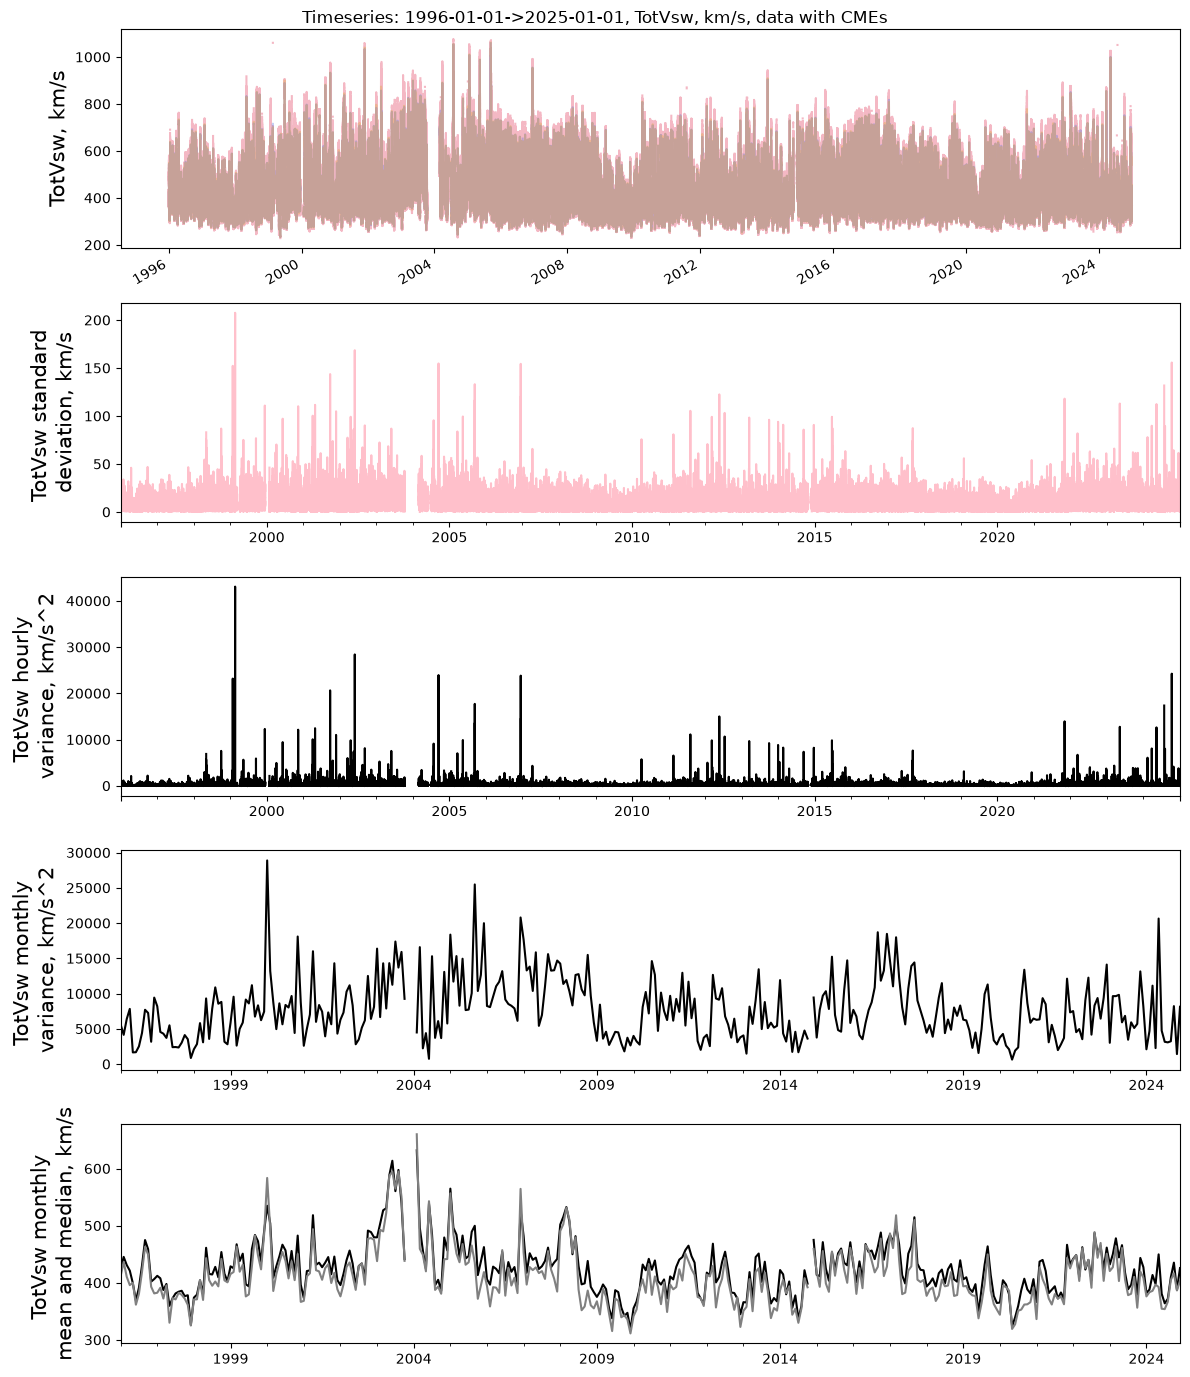

In [ ]:
fig, axs = plt.subplots(5,1, figsize = [12,14])#, sharex=True)

beginning = "1996-01-01"
ending = "2025-01-01"
alpha_1 = 0.3

parameter = "TotVsw"
parameter_unit = "km/s"

xLim = [windData[(windData.index >= beginning) & (windData.index <= ending)].index[0], windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]]

windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].plot(ax=axs[0], color = "crimson", label = "Minutely data", alpha = alpha_1)
windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean", alpha = alpha_1)
windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median", alpha = alpha_1)

windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")

windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")

windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("ME").var().plot(ax=axs[3], color = "black", label = "Monthly var")

windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("ME").mean().plot(ax=axs[4], color = "black", label = "Monthly mean")
windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("ME").median().plot(ax=axs[4], color = "grey", label = "Monthly median")


axs[0].set_ylabel(str(parameter) + ", "+str(parameter_unit), fontsize = subplotFont)
axs[1].set_ylabel(str(parameter) + " standard \ndeviation, " +str(parameter_unit), fontsize = subplotFont)
axs[2].set_ylabel(str(parameter) + " hourly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[3].set_ylabel(str(parameter) + " monthly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[4].set_ylabel(str(parameter) + " monthly \nmean and median, " +str(parameter_unit) , fontsize = subplotFont)
# axs[0].set_ylim([300, 700])
# axs[1].set_ylim([0, 20])
# axs[2].set_ylim([0, 350])
# axs[3].set_ylim([0, 350])

# for i in range(0,4):
#     axs[i].legend(loc="upper left")
#     axs[i].set_xlim(xLim)

# plt.legend()
plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending) +", " + str(parameter) +", "+ str(parameter_unit) + ", data with CMEs", fontsize = 12)
plt.tight_layout()
plt.show()


# Specific timeframes

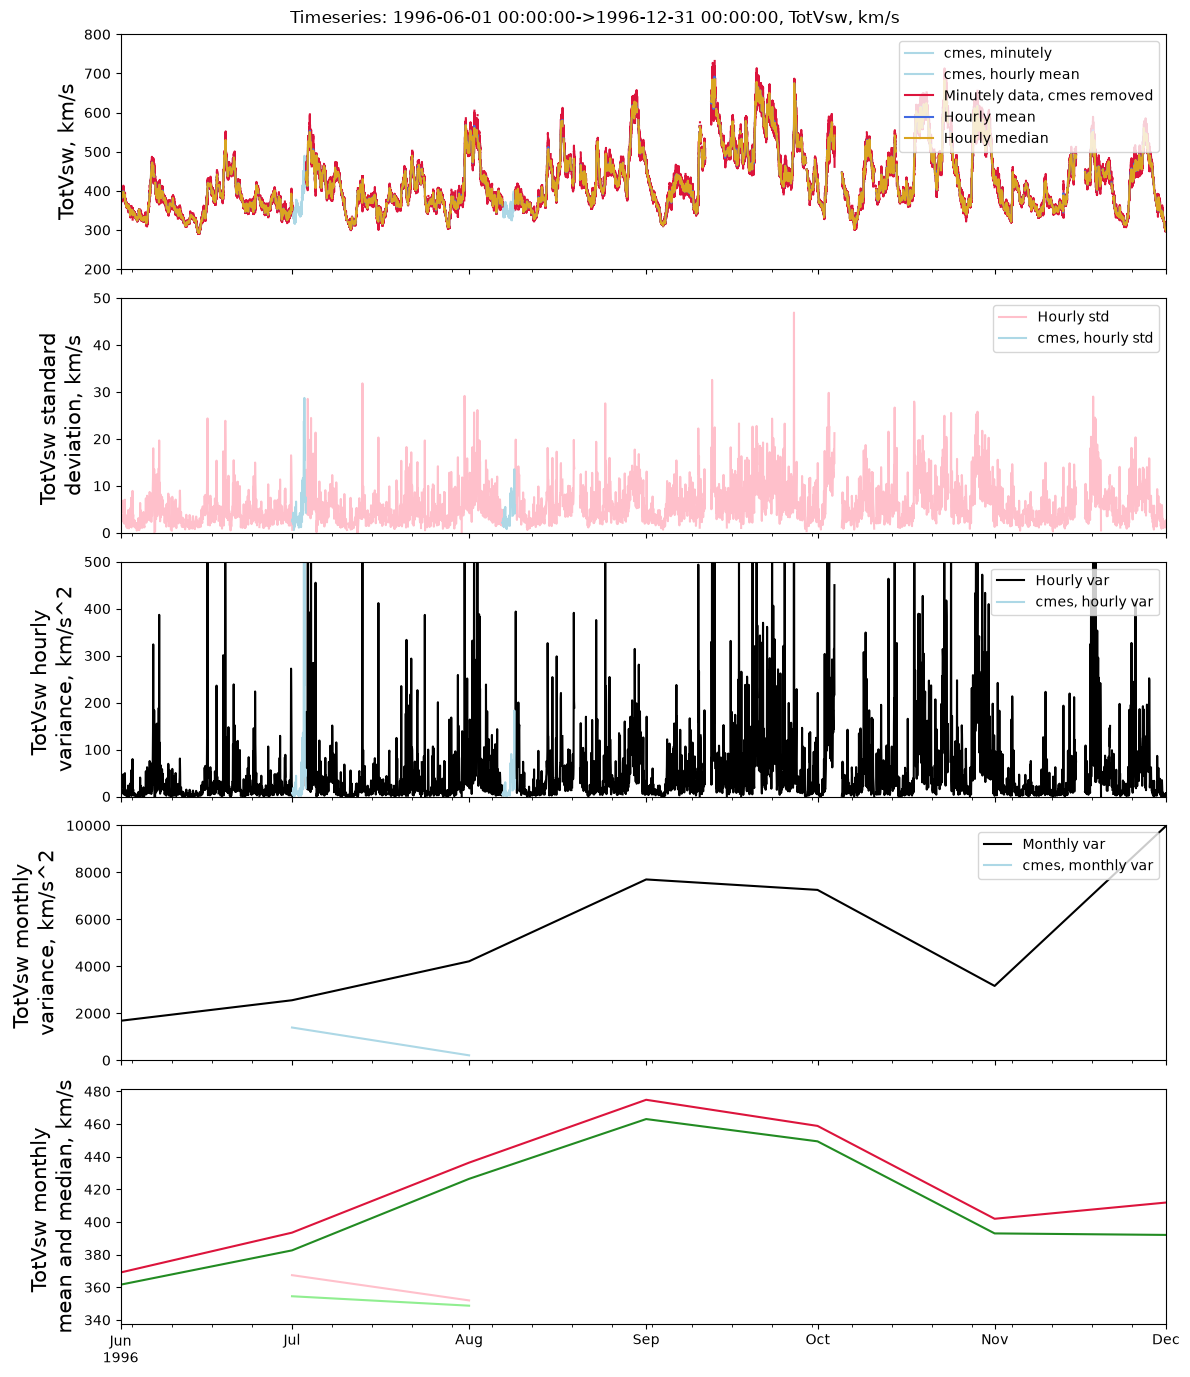

In [129]:
fig, axs = plt.subplots(5,1, figsize = [12,14], sharex=True)

beginning = "1996-06-01 00:00:00"
ending = "1996-12-31 00:00:00"

parameter = "TotVsw"
parameter_unit = "km/s"

timecropped = windData[(windData.index > beginning) & (windData.index < ending)]

no_cmes = timecropped.where(timecropped["cmes"] == 0)
cmes =  timecropped.where((timecropped["cmes"] == 1)|(timecropped["cmes"] == 2))
# checks = ["2024-12-31 15:30:00", "2024-12-31 17:30:00"]
# print(timecropped["cmes"][checks[0]:checks[1]])
# print(no_cmes["cmes"][checks[0]:checks[1]])
# print(cmes["cmes"][checks[0]:checks[1]])

# timecropped[parameter].plot(ax=axs[0], color = "grey", label = "All data")
cmes[parameter].plot(ax=axs[0], color = "lightblue", label = "cmes, minutely")
cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "lightblue", label = "cmes, hourly mean")


no_cmes[parameter].plot(ax=axs[0], color = "crimson", label = "Minutely data, cmes removed")
no_cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean")
no_cmes[parameter].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median")

no_cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")
cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "lightblue", label = "cmes, hourly std")

no_cmes[parameter].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")
cmes[parameter].resample("1h").var().plot(ax=axs[2] , color = "lightblue", label = "cmes, hourly var")

no_cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "black", label = "Monthly var")
cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "lightblue", label = "cmes, monthly var")

no_cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "crimson", label = "Monthly mean")
cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "pink", label = "cmes, monthly mean")
no_cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "forestgreen", label = "Monthly median")
cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "lightgreen", label = "cmes, monthly median")

axs[0].set_ylabel(str(parameter) + ", "+str(parameter_unit), fontsize = subplotFont)
axs[1].set_ylabel(str(parameter) + " standard \ndeviation, " +str(parameter_unit), fontsize = subplotFont)
axs[2].set_ylabel(str(parameter) + " hourly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[3].set_ylabel(str(parameter) + " monthly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[4].set_ylabel(str(parameter) + " monthly \nmean and median, " +str(parameter_unit) , fontsize = subplotFont)

axs[0].set_ylim(totvsw_ylim_min)
axs[1].set_ylim(totvsw_ylim_std)
axs[2].set_ylim(totvsw_ylim_hourlyvar2)
axs[3].set_ylim(totvsw_ylim_monthlyvar2)

for i in range(0,4):
    axs[i].legend(loc="upper right")
    # axs[i].set_xlim(xLim)

plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending) +", " + str(parameter) +", "+ str(parameter_unit), fontsize = 12)
plt.tight_layout()
plt.show()


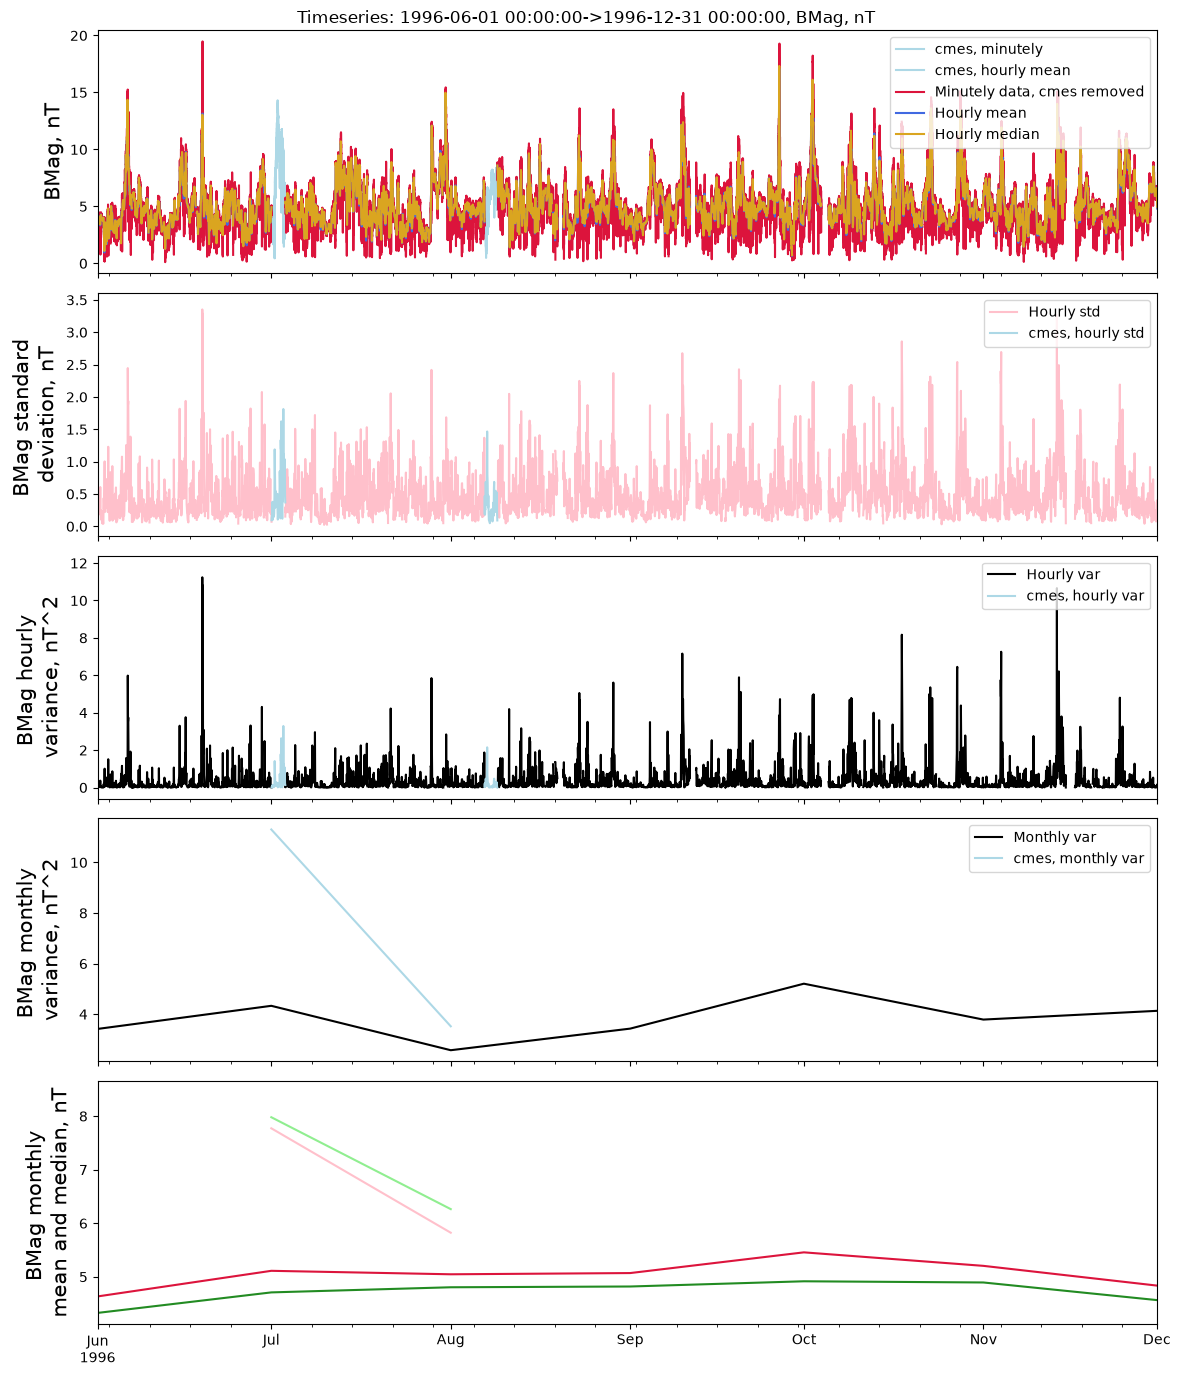

In [130]:
fig, axs = plt.subplots(5,1, figsize = [12,14], sharex=True)

beginning = "1996-06-01 00:00:00"
ending = "1996-12-31 00:00:00"

parameter = "BMag"
parameter_unit = "nT"

timecropped = windData[(windData.index > beginning) & (windData.index < ending)]

no_cmes = timecropped.where(timecropped["cmes"] == 0)
cmes =  timecropped.where((timecropped["cmes"] == 1)|(timecropped["cmes"] == 2))
# checks = ["2024-12-31 15:30:00", "2024-12-31 17:30:00"]
# print(timecropped["cmes"][checks[0]:checks[1]])
# print(no_cmes["cmes"][checks[0]:checks[1]])
# print(cmes["cmes"][checks[0]:checks[1]])

# timecropped[parameter].plot(ax=axs[0], color = "grey", label = "All data")
cmes[parameter].plot(ax=axs[0], color = "lightblue", label = "cmes, minutely")
cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "lightblue", label = "cmes, hourly mean")


no_cmes[parameter].plot(ax=axs[0], color = "crimson", label = "Minutely data, cmes removed")
no_cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean")
no_cmes[parameter].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median")

no_cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")
cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "lightblue", label = "cmes, hourly std")

no_cmes[parameter].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")
cmes[parameter].resample("1h").var().plot(ax=axs[2] , color = "lightblue", label = "cmes, hourly var")

no_cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "black", label = "Monthly var")
cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "lightblue", label = "cmes, monthly var")

no_cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "crimson", label = "Monthly mean")
cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "pink", label = "cmes, monthly mean")
no_cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "forestgreen", label = "Monthly median")
cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "lightgreen", label = "cmes, monthly median")

axs[0].set_ylabel(str(parameter) + ", "+str(parameter_unit), fontsize = subplotFont)
axs[1].set_ylabel(str(parameter) + " standard \ndeviation, " +str(parameter_unit), fontsize = subplotFont)
axs[2].set_ylabel(str(parameter) + " hourly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[3].set_ylabel(str(parameter) + " monthly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[4].set_ylabel(str(parameter) + " monthly \nmean and median, " +str(parameter_unit) , fontsize = subplotFont)

# axs[0].set_ylim(totvsw_ylim_min)
# axs[1].set_ylim(totvsw_ylim_std)
# axs[2].set_ylim(totvsw_ylim_hourlyvar2)
# axs[3].set_ylim(totvsw_ylim_monthlyvar2)

for i in range(0,4):
    axs[i].legend(loc="upper right")
    # axs[i].set_xlim(xLim)

plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending) +", " + str(parameter) +", "+ str(parameter_unit), fontsize = 12)
plt.tight_layout()
plt.show()


In [131]:
windData.columns

Index(['Year', 'DOY', 'Hour', 'Minute', 'IMF_PTS', 'PercentInterp',
       'CP/MVFlag', 'Timeshift', 'PFN_XGSE', 'PFN_YGSE', 'PFN_ZGSE', 'ScalarB',
       'Bx_GSEGSM', 'ByGSE', 'BzGSE', 'ByGSM', 'BzGSM', 'RMSTimeshift',
       'RMS_PFN', 'RMSScalarB', 'RMSFieldVector', 'Plasma_PTS', 'FlowSpeed',
       'Vx_GSE', 'Vy_GSE', 'Vz_GSE', 'ProtonDensity', 'Temp', 'X_s_c_GSE',
       'Y_s_c_GSE', 'Z_s_c_GSE', 'X_targ_GSE', 'Y_targ_GSE', 'Z_targ_GSE',
       'RMS_targ', 'DBOT1', 'DBOT2', 'TotVsw', 'BMag', 'vA_kms', 'Ma',
       'Pdyn_nPa', 'beta', 'cone_deg', 'clock_deg', 'r', 'lat', 'cmes',
       'sw_type'],
      dtype='str')

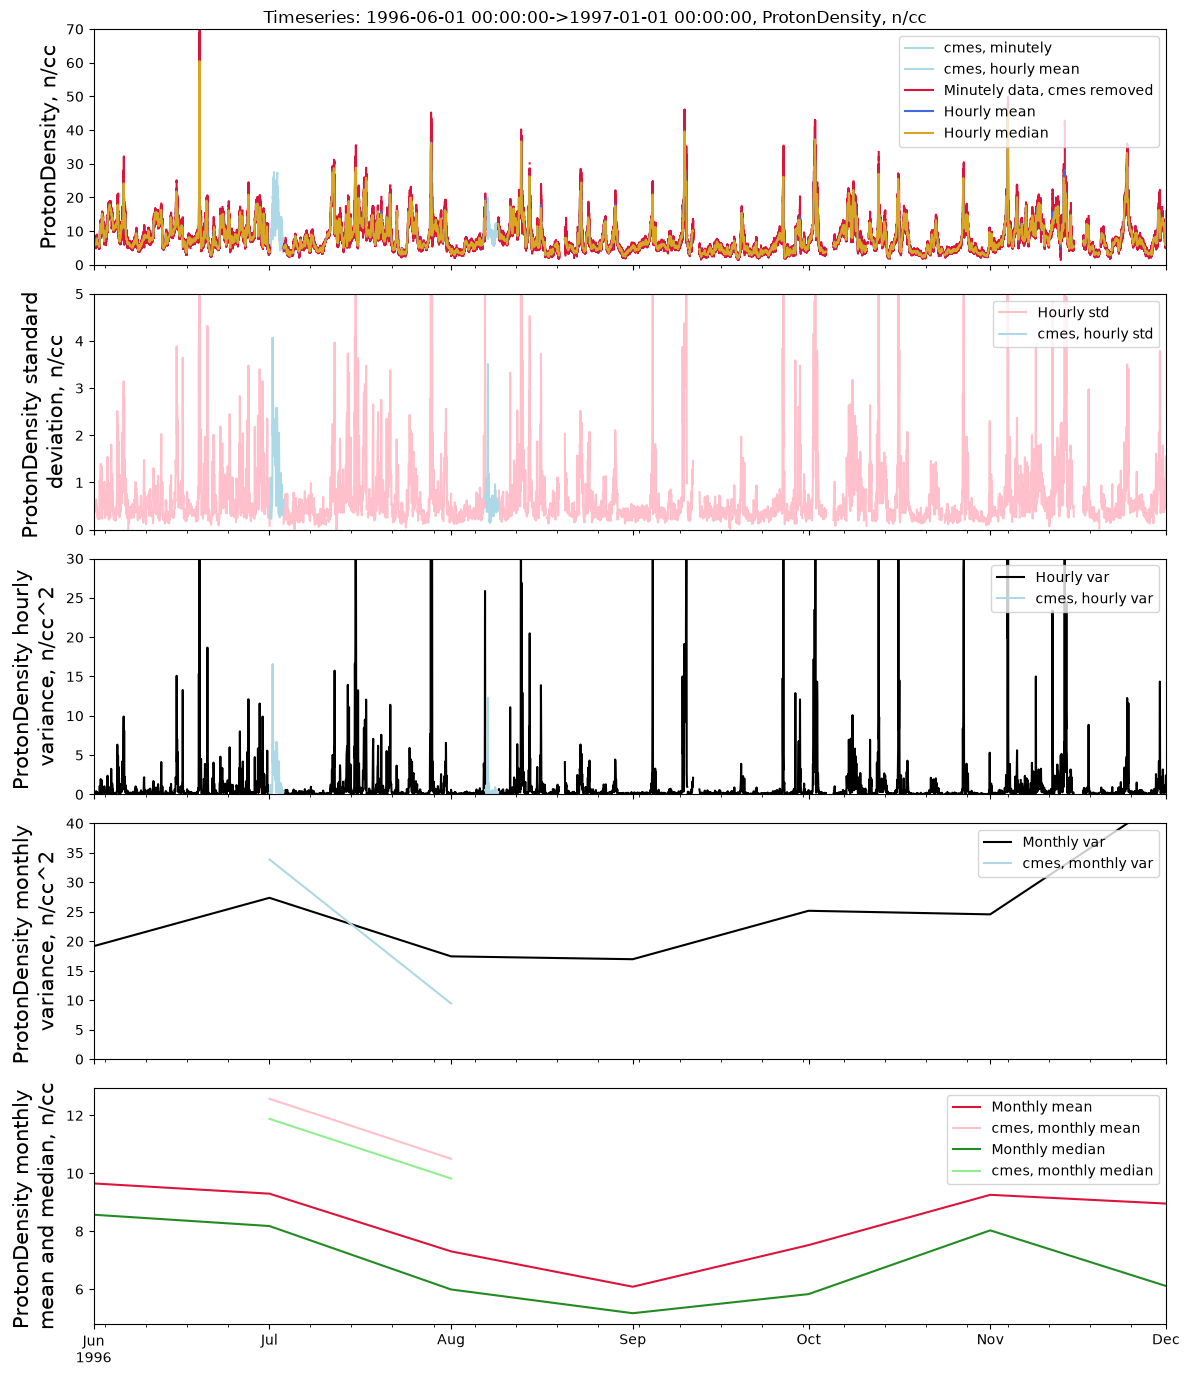

In [196]:
fig, axs = plt.subplots(5,1, figsize = [12,14], sharex=True)

beginning = "1996-06-01 00:00:00"
ending = "1997-01-01 00:00:00"

parameter = "ProtonDensity"
parameter_unit = "n/cc"

timecropped = windData[(windData.index > beginning) & (windData.index < ending)]

no_cmes = timecropped.where(timecropped["cmes"] == 0)
cmes =  timecropped.where((timecropped["cmes"] == 1)|(timecropped["cmes"] == 2))
# checks = ["2024-12-31 15:30:00", "2024-12-31 17:30:00"]
# print(timecropped["cmes"][checks[0]:checks[1]])
# print(no_cmes["cmes"][checks[0]:checks[1]])
# print(cmes["cmes"][checks[0]:checks[1]])

# timecropped[parameter].plot(ax=axs[0], color = "grey", label = "All data")
cmes[parameter].plot(ax=axs[0], color = "lightblue", label = "cmes, minutely")
cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "lightblue", label = "cmes, hourly mean")

no_cmes[parameter].plot(ax=axs[0], color = "crimson", label = "Minutely data, cmes removed")
no_cmes[parameter].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean")
no_cmes[parameter].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median")

no_cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")
cmes[parameter].resample("1h").std().plot(ax=axs[1] , color = "lightblue", label = "cmes, hourly std")

no_cmes[parameter].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")
cmes[parameter].resample("1h").var().plot(ax=axs[2] , color = "lightblue", label = "cmes, hourly var")

no_cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "black", label = "Monthly var")
cmes[parameter].resample("ME").var().plot(ax=axs[3], color = "lightblue", label = "cmes, monthly var")

no_cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "crimson", label = "Monthly mean")
cmes[parameter].resample("ME").mean().plot(ax=axs[4], color = "pink", label = "cmes, monthly mean")
no_cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "forestgreen", label = "Monthly median")
cmes[parameter].resample("ME").median().plot(ax=axs[4], color = "lightgreen", label = "cmes, monthly median")

axs[0].set_ylabel(str(parameter) + ", "+str(parameter_unit), fontsize = subplotFont)
axs[1].set_ylabel(str(parameter) + " standard \ndeviation, " +str(parameter_unit), fontsize = subplotFont)
axs[2].set_ylabel(str(parameter) + " hourly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[3].set_ylabel(str(parameter) + " monthly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont)
axs[4].set_ylabel(str(parameter) + " monthly \nmean and median, " +str(parameter_unit) , fontsize = subplotFont)

axs[0].set_ylim(pro_dens_ylim_min)
axs[1].set_ylim(pro_dens_ylim_std)
axs[2].set_ylim(pro_dens_ylim_hourlyvar1)
axs[3].set_ylim(pro_dens_ylim_monthlyvar2)

for i in range(0,5):
    axs[i].legend(loc="upper right")
    # axs[i].set_xlim(xLim)

plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending) +", " + str(parameter) +", "+ str(parameter_unit), fontsize = 12)
plt.tight_layout()
plt.show()


# Solar cycles

In [159]:
#######Sunspot cycle
# get data
time_range = TimeRange("1994-01-01 00:00", Time.now()) # I've used the start of the year before the C23 minimum that Tindale and Chapman (2017) use
result = Fido.search(a.Time(time_range), a.Instrument('noaa-indices')) # fido search for the noaa indices in the time range
f_noaa_indices = Fido.fetch(result)
result = Fido.search(a.Time(time_range.end, time_range.end + TimeDelta(4 * u.year)),
                     a.Instrument('noaa-predict')) # get the predicted sunspot numbers from NOAA (4 years in future)
f_noaa_predict = Fido.fetch(result)

#loading data into TimeSeries objects
noaa = ts.TimeSeries(f_noaa_indices, source='noaaindices').truncate(time_range) 
noaa_predict = ts.TimeSeries(f_noaa_predict, source='noaapredictindices')

TitleSize = 25
AxisSize = 20
TickSize = 15

Files Downloaded: 100%|██████████| 1/1 [00:00<00:00,  7.17file/s]


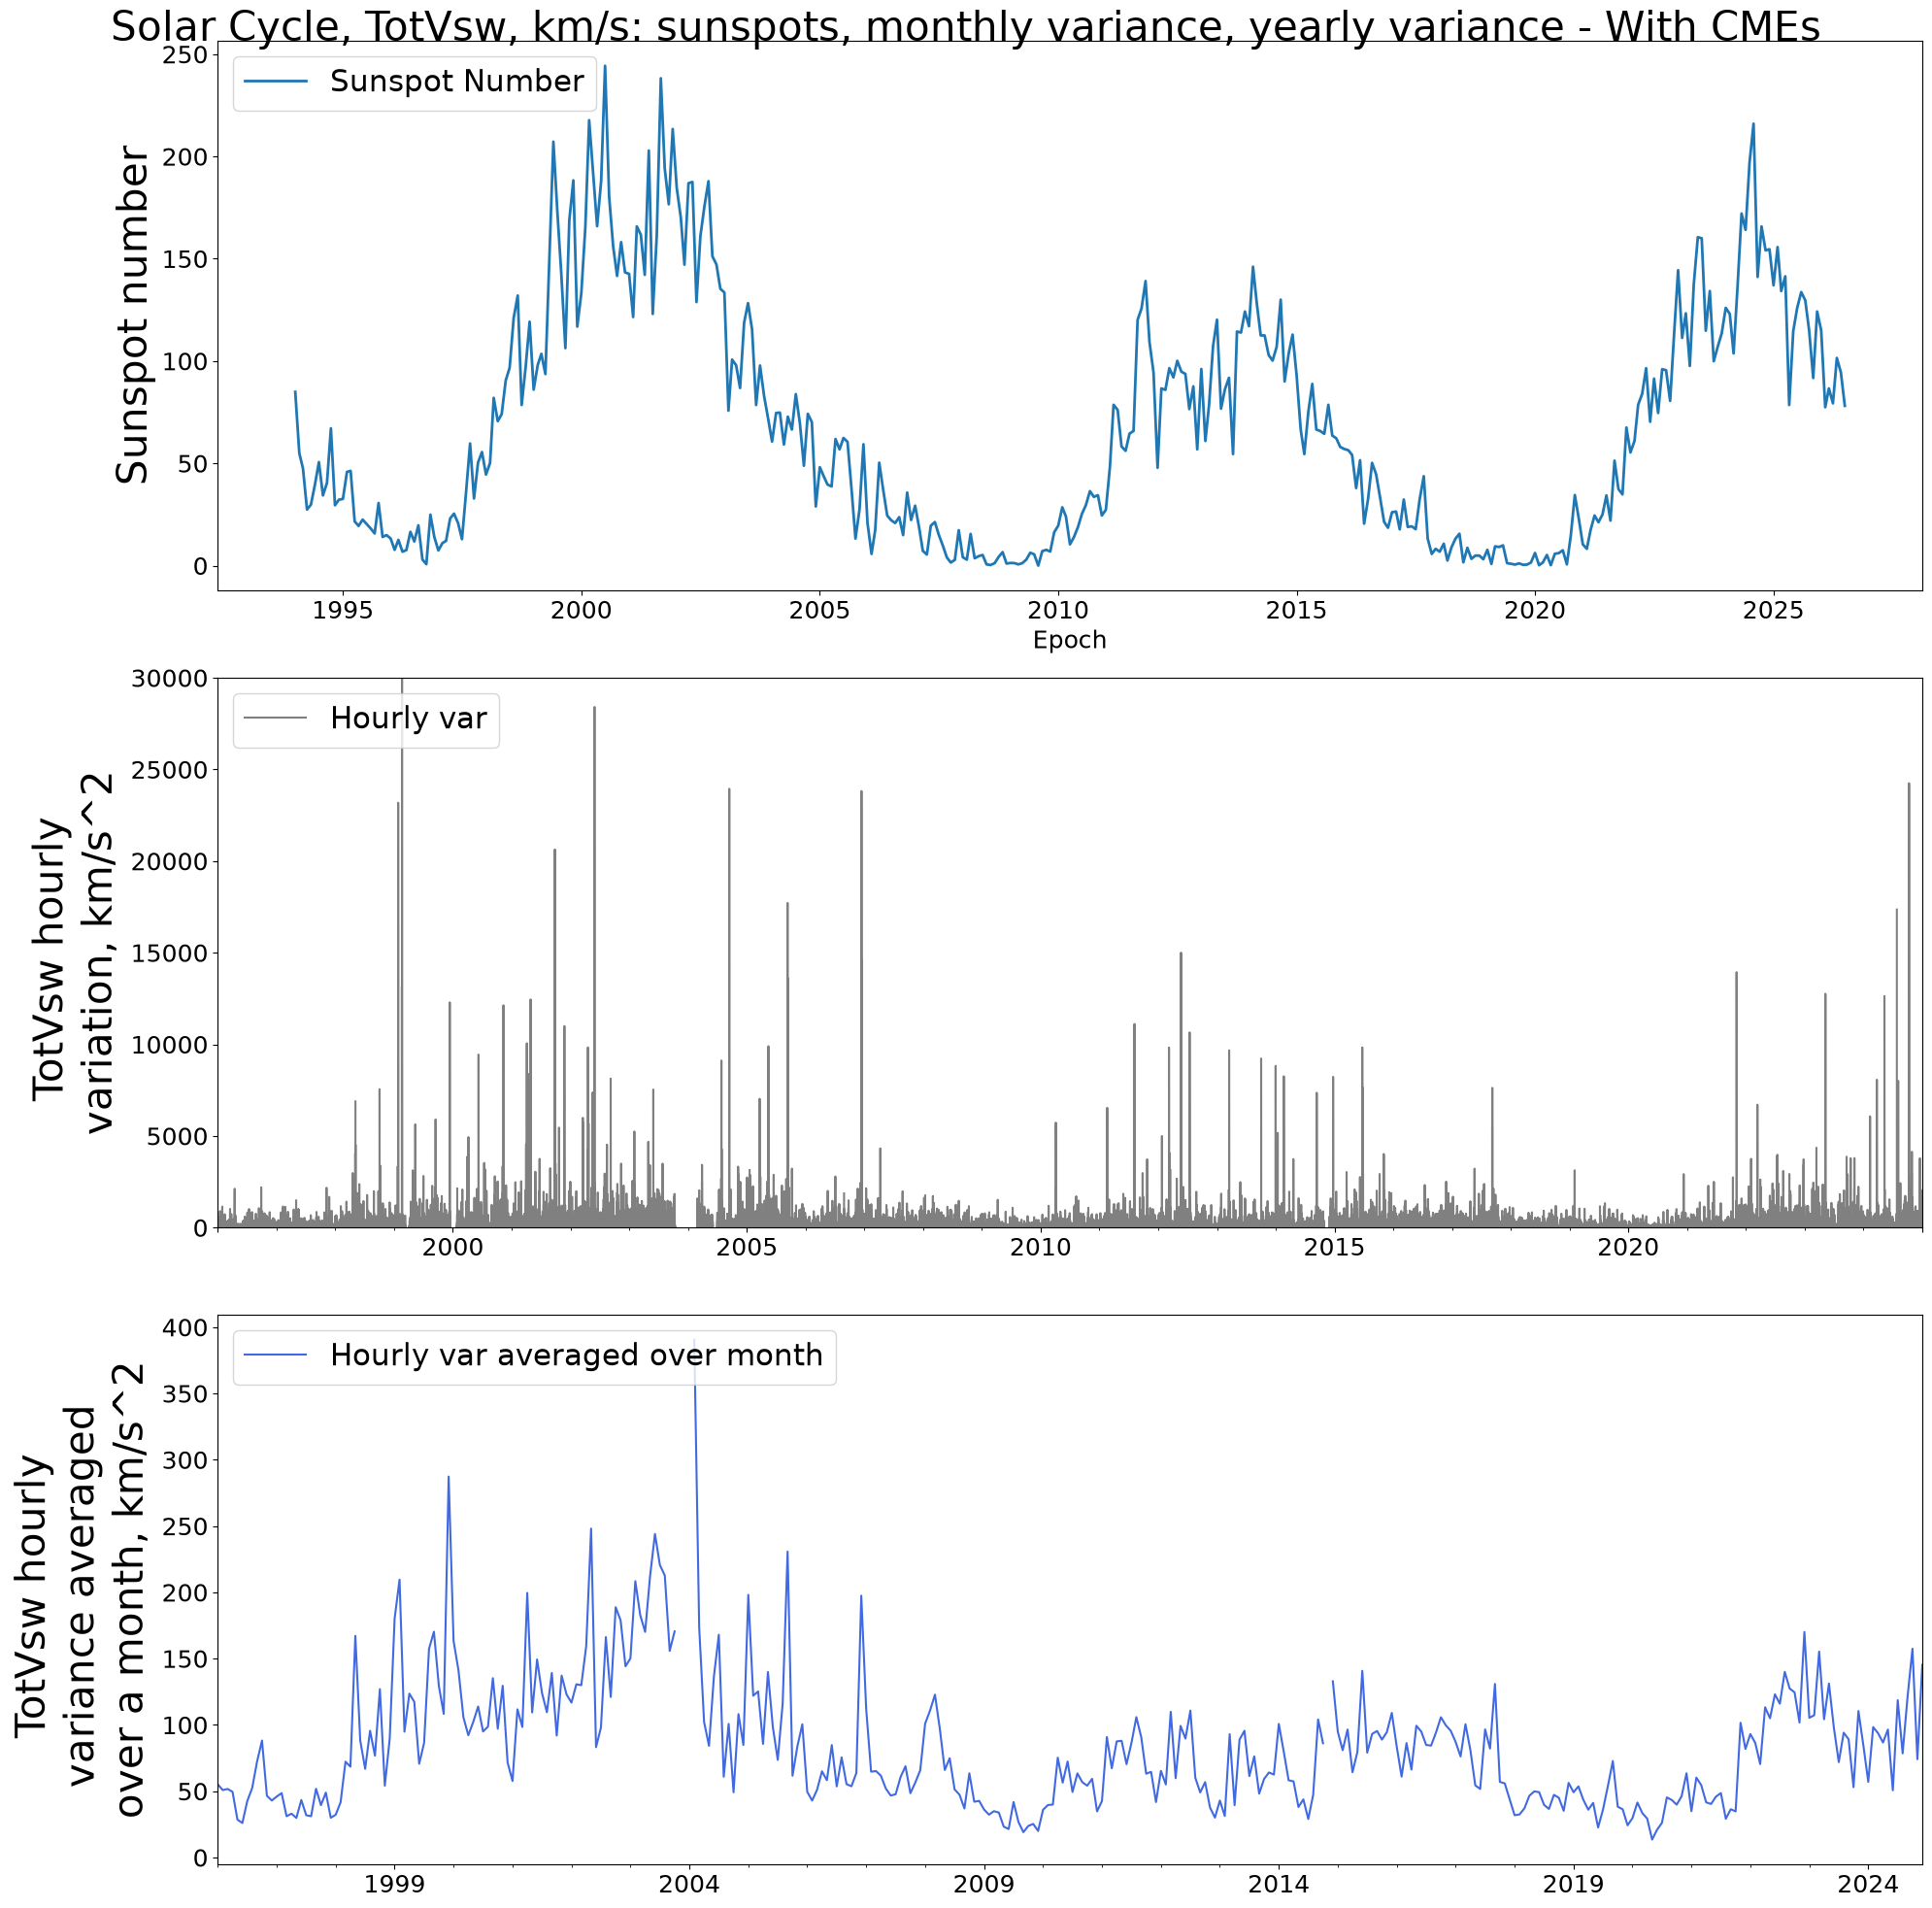

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(20,20)) #(20,12))

#######Sunspot cycle

time_support()
ax[0].plot(noaa.time, noaa.quantity('sunspot RI'), label='Sunspot Number', linewidth=2)
ax[0].set_ylabel('Sunspot Number', fontsize=18)
ax[0].set_xlabel('Epoch', fontsize=18)

times = [datetime(1995,1,1), datetime(2000,1,1), datetime(2005,1,1), datetime(2010,1,1), datetime(2015,1,1), datetime(2020,1,1), datetime(2025,1,1)]
t_yr = [tm.year for tm in times]
t=Time(times, format='datetime')
ax[0].set_xticks(t,t_yr)
# ax[1].set_xticks(t,t_yr)

#######Sunspot cycle

####### Parameter
beginning = "1996-01-01"
ending = "2025-01-01"
alpha_1 = 0.3

parameter = "TotVsw"
parameter_unit = "km/s"

# xLim = [windData[(windData.index >= beginning) & (windData.index <= ending)].index[0], windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]]

timecropped2 = windData[(windData.index >= beginning) & (windData.index <= ending)]

#######Monthly variance
hourly_var = timecropped2[parameter].resample("1h").var()
monthly_var = timecropped2[parameter].resample("ME").var()

hourly_var.plot(ax=ax[1], color = "grey", label = "Hourly var")
# monthly_var.plot(ax=ax[1], color = "royalblue", label = "Monthly var")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("2QE").var().plot(ax=ax[1], color = "red", label = "6 monthly var")

# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[1], color = "red", label = "Yearly var")


#######Yearly variance
avgMHVar = hourly_var.resample("MS").mean()
# hourly_var.plot(ax=ax[2], color = "grey", label = "Hourly var")
avgMHVar.plot(ax=ax[2], color = "royalblue", label = "Hourly var averaged over month")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[2], color = "royalblue", label = "Yearly var")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[2], color = "black", label = "Monthly var")



ax[0].set_ylabel("Sunspot number", fontsize = subplotFont*2)
ax[1].set_ylabel(str(parameter) + " hourly \nvariation, " +str(parameter_unit) +"^2", fontsize = subplotFont*2)
ax[2].set_ylabel(str(parameter) + " hourly \nvariance averaged \nover a month, " +str(parameter_unit) +"^2" , fontsize = subplotFont*2)


ax[1].set_ylim([0, 30000])
# ax[2].set_ylim([0, 500])

# ax[1].set_ylim([0, 30000])
# ax[2].set_ylim([0, 20000])

for i in range(0,3):
    ax[i].legend(loc="upper left", fontsize = subplotFont*1.5)
    ax[i].tick_params(labelsize=18)

plt.suptitle("Solar Cycle, "+str(parameter)+ ", "+str(parameter_unit) + ": sunspots, monthly variance, yearly variance - With CMEs", fontsize = titleFont*2)
plt.tight_layout()
plt.show()

# Remove CMEs

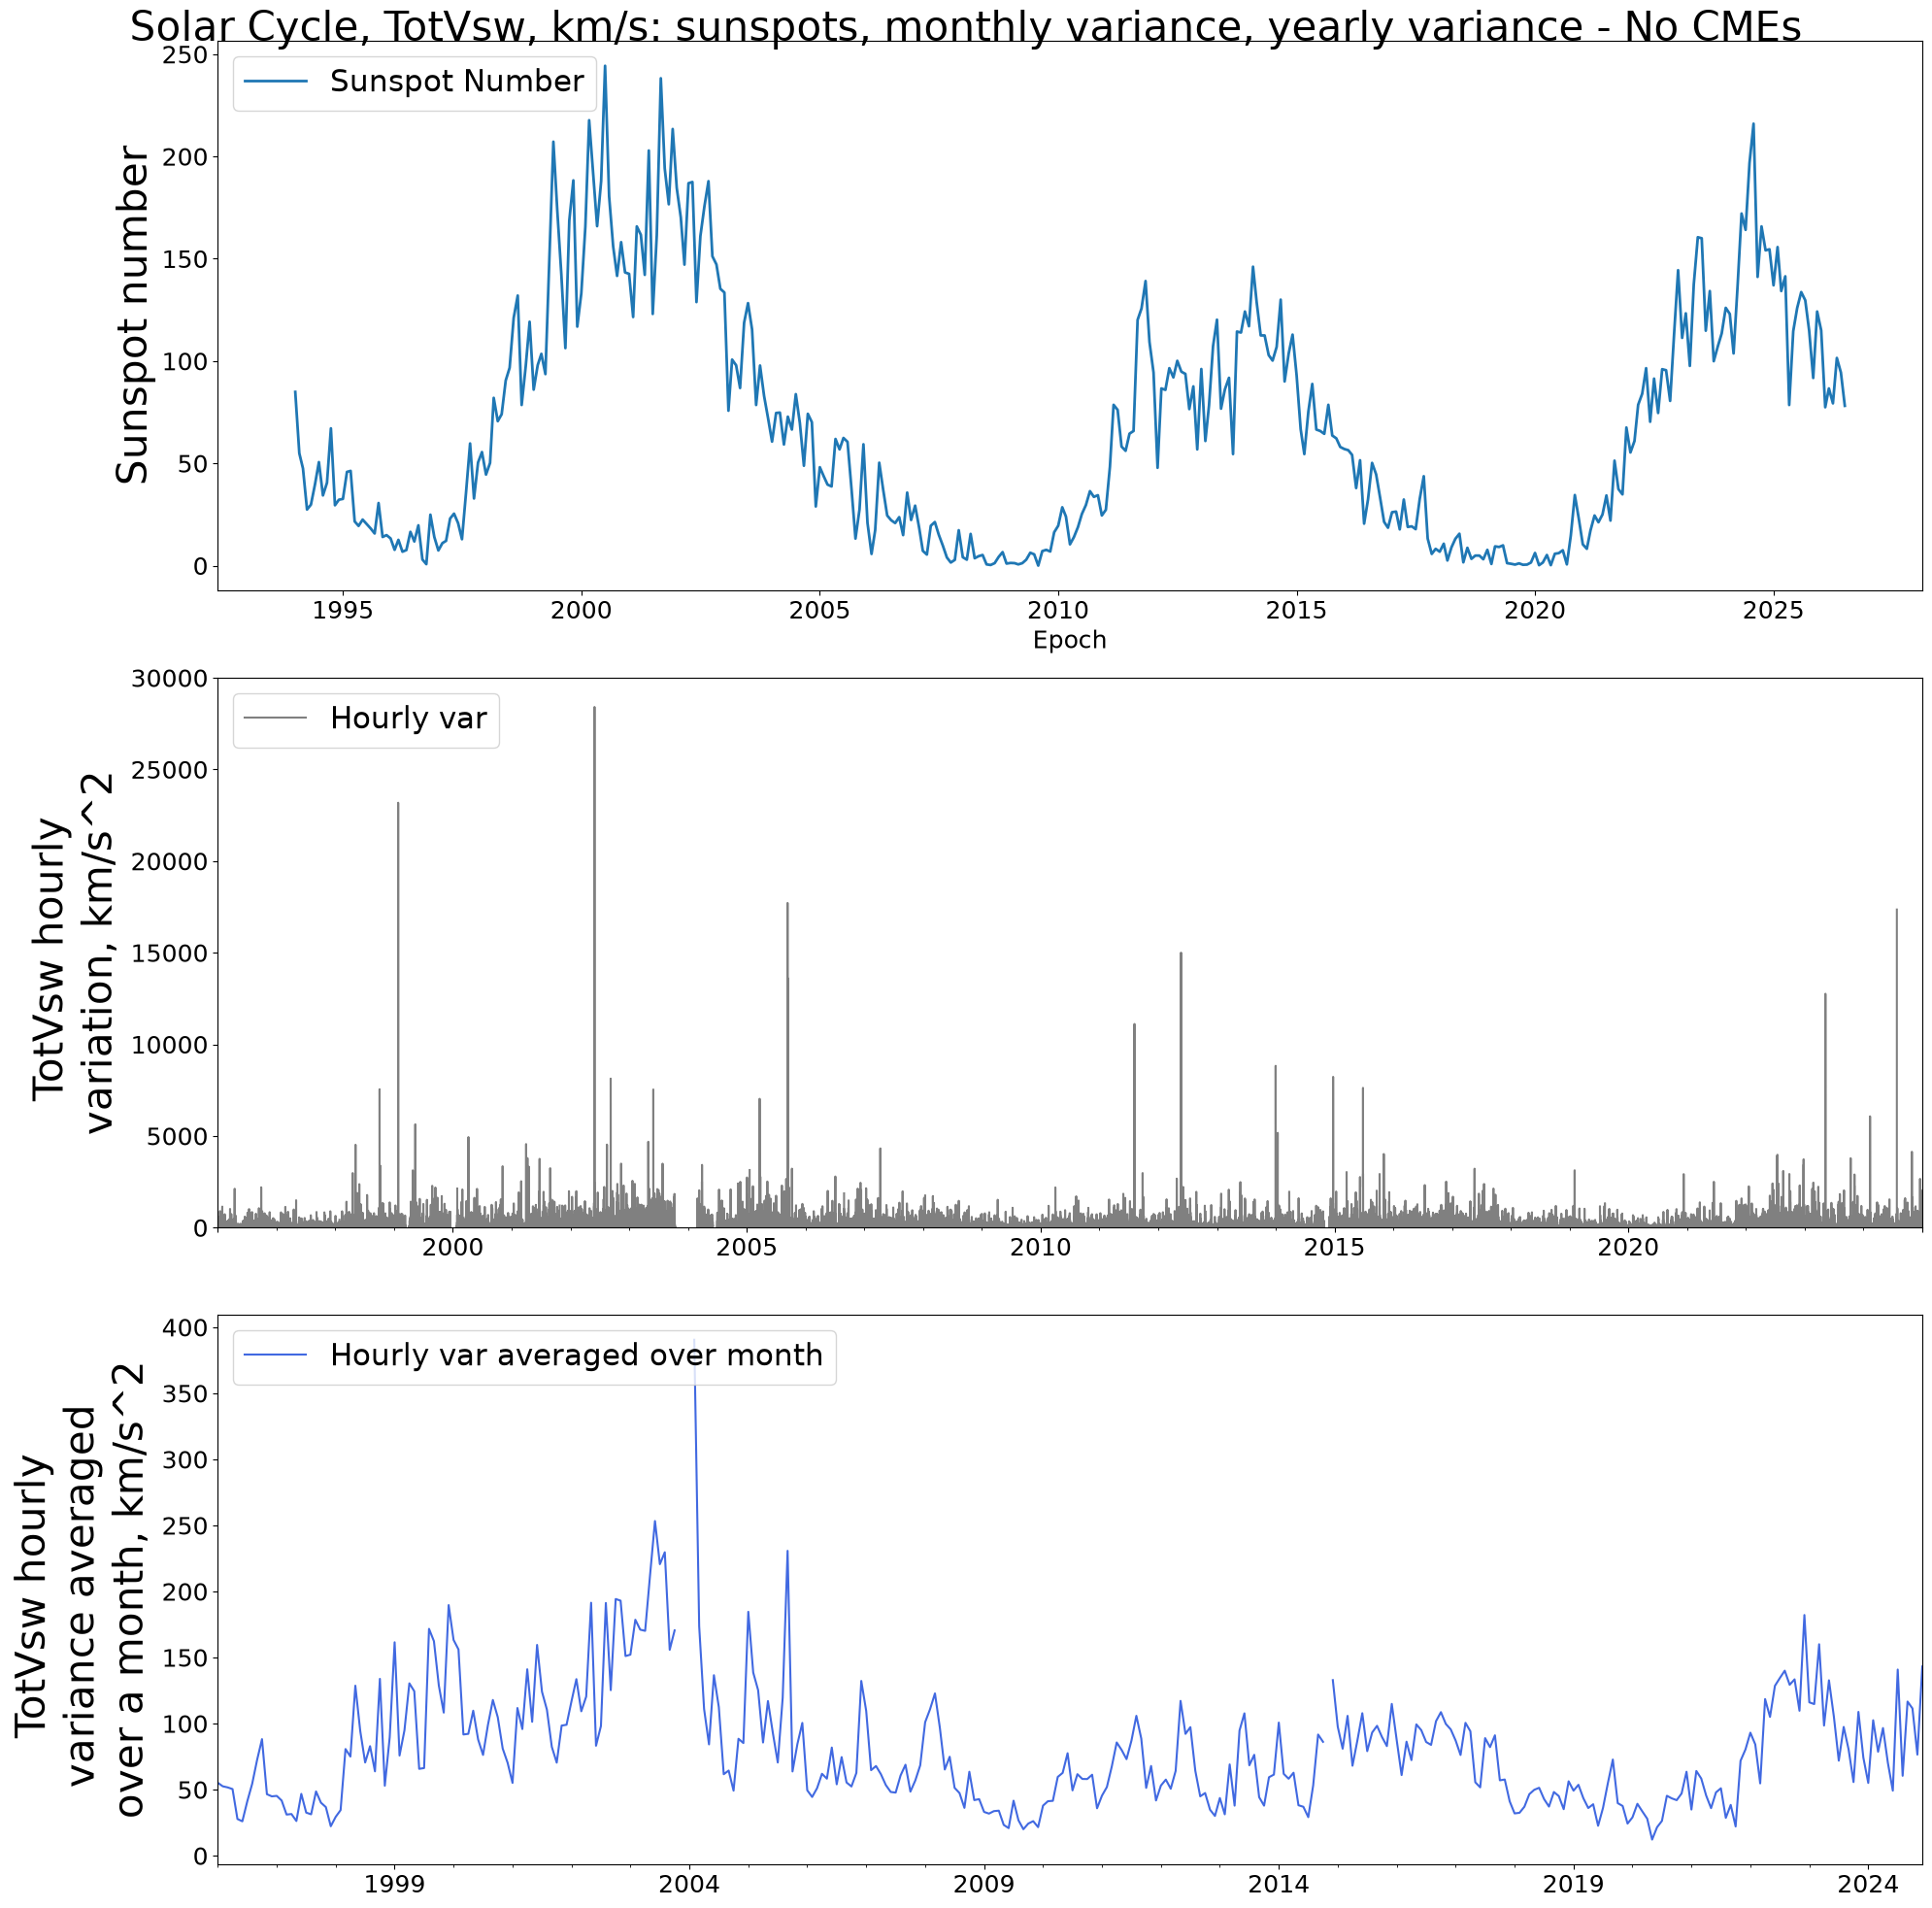

In [216]:
fig, ax = plt.subplots(3, 1, figsize=(20,20)) #(20,12))

#######Sunspot cycle

time_support()
ax[0].plot(noaa.time, noaa.quantity('sunspot RI'), label='Sunspot Number', linewidth=2)
ax[0].set_ylabel('Sunspot Number', fontsize=18)
ax[0].set_xlabel('Epoch', fontsize=18)

times = [datetime(1995,1,1), datetime(2000,1,1), datetime(2005,1,1), datetime(2010,1,1), datetime(2015,1,1), datetime(2020,1,1), datetime(2025,1,1)]
t_yr = [tm.year for tm in times]
t=Time(times, format='datetime')
ax[0].set_xticks(t,t_yr)
# ax[1].set_xticks(t,t_yr)

#######Sunspot cycle

####### Parameter
beginning = "1996-01-01"
ending = "2025-01-01"
alpha_1 = 0.3

parameter = "TotVsw"
parameter_unit = "km/s"

# xLim = [windData[(windData.index >= beginning) & (windData.index <= ending)].index[0], windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]]

timecropped3 = windData[(windData.index >= beginning) & (windData.index <= ending)]
no_cmes = timecropped3.where(timecropped3["cmes"] == 0)
cmes =  timecropped3.where((timecropped3["cmes"] == 1)|(timecropped3["cmes"] == 2))

#######Monthly variance
hourly_var = no_cmes[parameter].resample("1h").var()
monthly_var = no_cmes[parameter].resample("ME").var()

hourly_var.plot(ax=ax[1], color = "grey", label = "Hourly var")
# monthly_var.plot(ax=ax[1], color = "royalblue", label = "Monthly var")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("2QE").var().plot(ax=ax[1], color = "red", label = "6 monthly var")

# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[1], color = "red", label = "Yearly var")


#######Yearly variance
avgMHVar = hourly_var.resample("MS").mean()
# hourly_var.plot(ax=ax[2], color = "grey", label = "Hourly var")
avgMHVar.plot(ax=ax[2], color = "royalblue", label = "Hourly var averaged over month")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[2], color = "royalblue", label = "Yearly var")
# windData[(windData.index >= beginning) & (windData.index <= ending)][parameter].resample("YE").var().plot(ax=ax[2], color = "black", label = "Monthly var")



ax[0].set_ylabel("Sunspot number", fontsize = subplotFont*2)
ax[1].set_ylabel(str(parameter) + " hourly \nvariation, " +str(parameter_unit) +"^2", fontsize = subplotFont*2)
ax[2].set_ylabel(str(parameter) + " hourly \nvariance averaged \nover a month, " +str(parameter_unit) +"^2" , fontsize = subplotFont*2)


ax[1].set_ylim([0, 30000])
# ax[2].set_ylim([0, 500])

# ax[1].set_ylim([0, 30000])
# ax[2].set_ylim([0, 20000])

for i in range(0,3):
    ax[i].legend(loc="upper left", fontsize = subplotFont*1.5)
    ax[i].tick_params(labelsize=18)

plt.suptitle("Solar Cycle, "+str(parameter)+ ", "+str(parameter_unit) + ": sunspots, monthly variance, yearly variance - No CMEs", fontsize = titleFont*2)
plt.tight_layout()
plt.show()

In [214]:
# fig, ax = plt.subplots(3, 1, figsize=(20,20)) #(20,12))


# #######Sunspot cycle

# time_support()
# ax[0].plot(noaa.time, noaa.quantity('sunspot RI'), label='Sunspot Number', linewidth=2)
# ax[0].set_ylabel('Sunspot Number', fontsize=18)
# ax[0].set_xlabel('Epoch', fontsize=18)

# times = [datetime(1995,1,1), datetime(2000,1,1), datetime(2005,1,1), datetime(2010,1,1), datetime(2015,1,1), datetime(2020,1,1), datetime(2025,1,1)]
# t_yr = [tm.year for tm in times]
# t=Time(times, format='datetime')
# ax[0].set_xticks(t,t_yr)
# # ax[1].set_xticks(t,t_yr)

# #######Sunspot cycle

# ####### Parameter
# beginning = "1996-01-01"
# ending = "2025-01-01"
# alpha_1 = 0.3

# parameter = "TotVsw"
# parameter_unit = "km/s"

# timecropped = windData[(windData.index > beginning) & (windData.index < ending)]

# no_cmes = timecropped.where(timecropped["cmes"] == 0)
# cmes =  timecropped.where((timecropped["cmes"] == 1)|(timecropped["cmes"] == 2))

# # xLim = [windData[(windData.index >= beginning) & (windData.index <= ending)].index[0], windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]]

# #######Monthly variance
# # no_cmes[parameter].resample("1h").var().plot(ax=ax[1], color = "grey", label = "Hourly var")
# no_cmes[parameter].resample("ME").var().plot(ax=ax[1], color = "royalblue", label = "Monthly var")
# no_cmes[parameter].resample("2QE").var().plot(ax=ax[1], color = "red", label = "6 monthly var")

# # no_cmes[parameter].resample("YE").var().plot(ax=ax[1], color = "red", label = "Yearly var")


# #######Yearly variance
# no_cmes[parameter].resample("YE").var().plot(ax=ax[2], color = "royalblue", label = "Yearly var")
# # no_cmes[parameter].resample("YE").var().plot(ax=ax[2], color = "black", label = "Monthly var")


# ax[0].set_ylabel("Sunspot number", fontsize = subplotFont*2)
# ax[1].set_ylabel(str(parameter) + " monthly \nvariation, " +str(parameter_unit) +"^2", fontsize = subplotFont*2)
# ax[2].set_ylabel(str(parameter) + " yearly \nvariance, " +str(parameter_unit) +"^2" , fontsize = subplotFont*2)

# ax[1].set_ylim([0, 30000])
# ax[2].set_ylim([0, 20000])
# # axs[1].set_ylim([0, 20])
# # axs[2].set_ylim([0, 350])
# # axs[3].set_ylim([0, 350])


# for i in range(0,3):
#     ax[i].legend(loc="upper left", fontsize = subplotFont*1.5)
#     ax[i].tick_params(labelsize=18)

# plt.suptitle("Solar Cycle, "+str(parameter)+ ", "+str(parameter_unit) + ": sunspots, monthly variance, yearly variance - No CMEs", fontsize = titleFont*2)
# plt.tight_layout()
# plt.show()